# Prophet Forecasting

Compare additive and multiplicative seasonality. Yearly seasonality is a cautious experiment; holiday effects remain disabled until calendar labels are verified.


Prophet's uncertainty bounds are model-based and depend on trend and seasonality assumptions; they do not guarantee future coverage. The built-in cross-validation below is a development diagnostic and does not replace the final chronological holdout. Yearly seasonality is disabled in the main candidates because the available history covers only about 16 months.


Importing plotly failed. Interactive plots will not work.


18:26:13 - cmdstanpy - INFO - Chain [1] start processing


18:26:13 - cmdstanpy - INFO - Chain [1] done processing


Chimi & Churri training-only interpolation dates: [Timestamp('2016-04-05 00:00:00'), Timestamp('2016-09-17 00:00:00')]


  0%|          | 0/7 [00:00<?, ?it/s]

18:26:13 - cmdstanpy - INFO - Chain [1] start processing


... (138 outputs left out)

18:26:18 - cmdstanpy - INFO - Chain [1] start processing


18:26:18 - cmdstanpy - INFO - Chain [1] done processing


development CV multiplicative 0.05 mean RMSE 18.519387400322564
Assa Frão selected on development CV: multiplicative 0.05 CV RMSE 18.519387400322564


single final holdout evaluation {'mae': 9.156994934484155, 'rmse': 13.194359471252913, 'wape': 0.25537436072266567, 'smape': 0.28238642506128814, 'mean_error': -3.9540806765325747, 'r2': 0.5483778504923402, 'mase': 0.4843640305643559}
serialization round-trip: Prophet


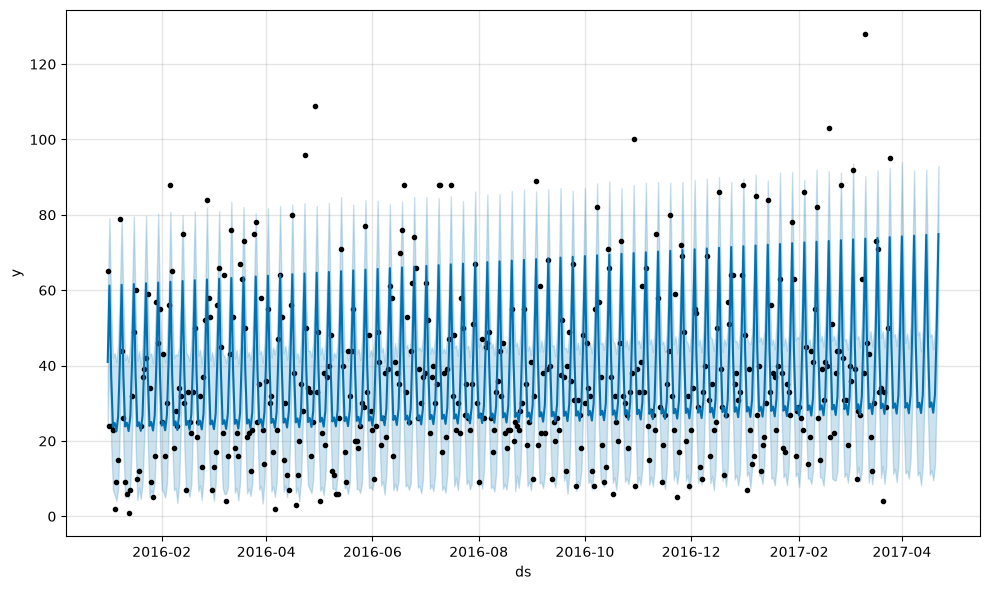

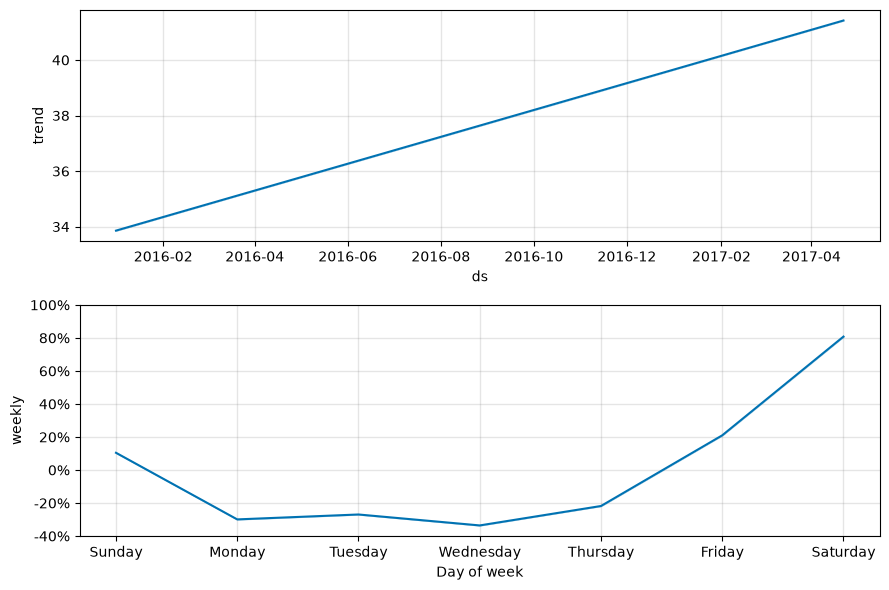

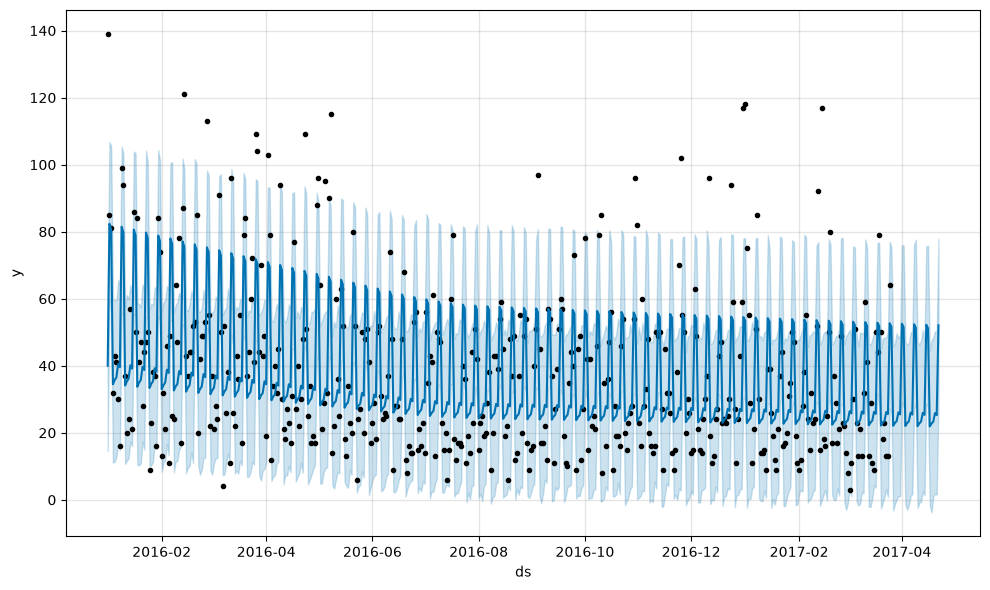

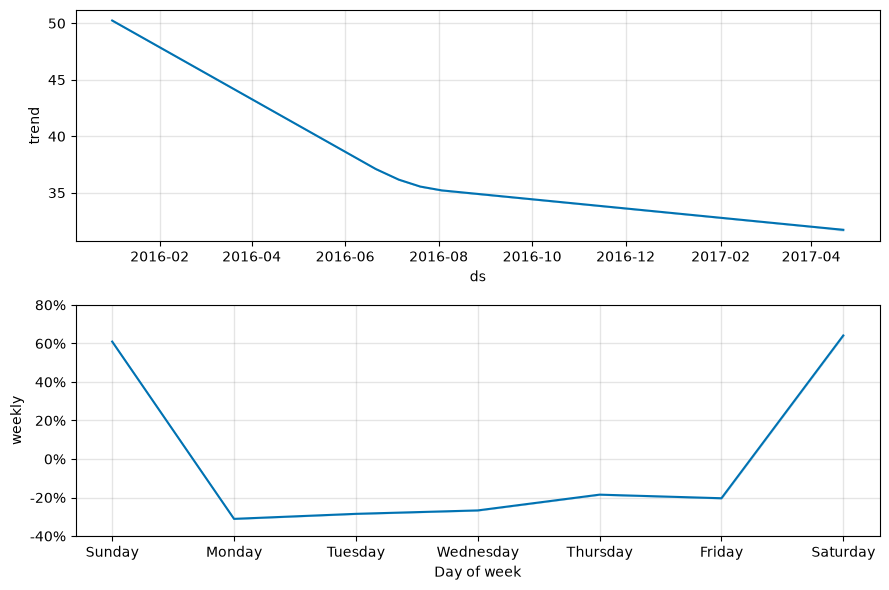

In [1]:
# PROJECT_ROOT_BOOTSTRAP: support kernels started from the repository root or notebooks/.
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Could not locate the project root containing src/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import pandas as pd
from pathlib import Path
from importlib.metadata import version
import json
from src.data import load_demand, TARGETS
from src.evaluation import chronological_holdout, forecast_metrics
from src.models.prophet_models import prophet_frame, make_model, future_frame
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.serialize import model_to_json, model_from_json

demand = load_demand("data/raw/clientes_restaurantes.csv")
forecast_rows = []
for target in TARGETS:
    train, test = chronological_holdout(demand[[target]], 28)
    # Impute an internal gap from training observations only; keep test missingness unchanged.
    missing_dates = train.index[train[target].isna()]
    print(target, "training-only interpolation dates:", missing_dates.tolist())
    train[target] = train[target].interpolate(limit_area="inside")
    train = train.dropna(subset=[target])
    candidates = []
    for mode in ("additive", "multiplicative"):
        for cp_scale in (0.01, 0.05):
            candidate = make_model(seasonality_mode=mode, yearly_seasonality=False, changepoint_prior_scale=cp_scale)
            candidate.fit(prophet_frame(train[target]))
            cv = cross_validation(candidate, initial="240 days", period="28 days", horizon="28 days", parallel=None)
            cv_metrics = performance_metrics(cv)
            cv_rmse = float(cv_metrics["rmse"].mean())
            candidates.append((cv_rmse, mode, cp_scale, candidate, cv_metrics))
            print("development CV", mode, cp_scale, "mean RMSE", cv_rmse)
    # Select on development cross-validation only; inspect the final holdout once.
    cv_rmse, mode, cp_scale, model, cv_metrics = min(candidates, key=lambda row: row[0])
    print(target, "selected on development CV:", mode, cp_scale, "CV RMSE", cv_rmse)
    forecast = model.predict(future_frame(model, len(test)))
    model.plot(forecast)
    model.plot_components(forecast)
    observed = test[target].to_numpy(dtype=float)
    prediction = forecast.tail(len(test))["yhat"].to_numpy()
    print("single final holdout evaluation", forecast_metrics(observed, prediction, train[target].to_numpy()))
    part = forecast.tail(len(test)).copy()
    part["restaurant"], part["model"], part["horizon"] = target, f"Prophet_{mode}_cp{cp_scale}", range(1, len(part) + 1)
    part = part.rename(columns={"ds": "date", "yhat": "prediction", "yhat_lower": "lower", "yhat_upper": "upper"})
    forecast_rows.append(part[["date", "restaurant", "model", "horizon", "prediction", "lower", "upper"]])
    payload = model_to_json(model)
    restored = model_from_json(payload)
    print("serialization round-trip:", type(restored).__name__)
    model_path = Path("artifacts/models") / f"prophet_{target.replace(' ', '_')}_selected.json"
    model_path.parent.mkdir(parents=True, exist_ok=True)
    model_path.write_text(payload)
    metadata = {"training_cutoff": str(train.index.max().date()), "parameters": {"mode": mode, "changepoint_prior_scale": cp_scale, "yearly_seasonality": False}, "validation_method": "development Prophet CV selection; one final chronological holdout evaluation", "forecast_horizon_days": len(test), "package_versions": {"prophet": version("prophet"), "pandas": version("pandas")}}
    model_path.with_suffix(".metadata.json").write_text(json.dumps(metadata, indent=2))
Path("artifacts/forecasts").mkdir(parents=True, exist_ok=True)
pd.concat(forecast_rows).to_csv("artifacts/forecasts/prophet_validation_forecasts.csv", index=False)
# Yearly seasonality remains a cautious separate sensitivity experiment because history spans only about 16 months.
# Holiday effects remain disabled pending semantic and future-availability checks.
